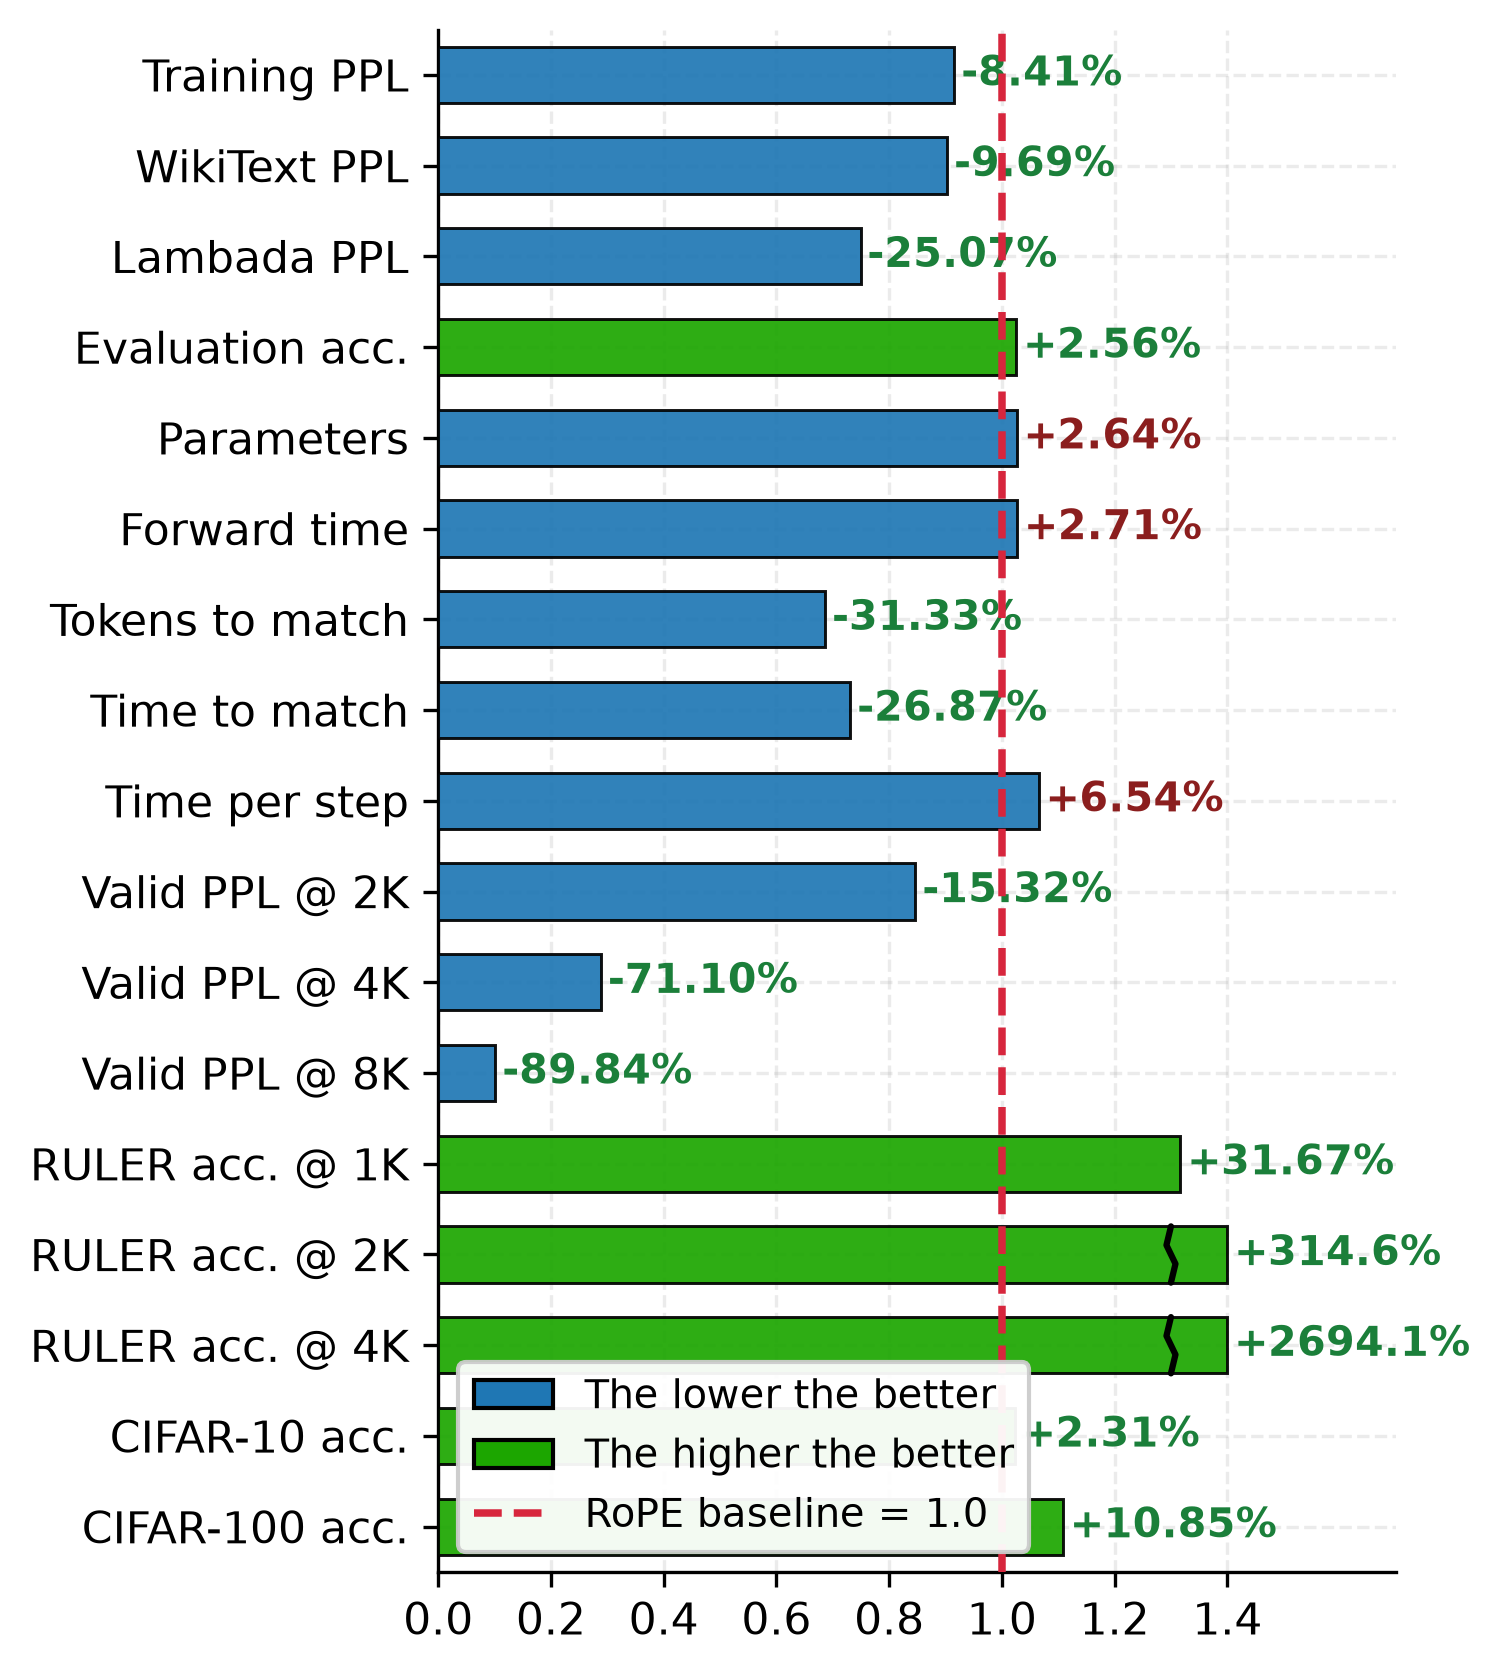

In [27]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import matplotlib as mpl
import math

mpl.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "grid.linestyle": "--",
        "axes.axisbelow": True,
    }
)

BLUE = "#1f77b4"
ORANGE = "#1ca600"
RED = "#D7263D"

rows = [
    ["Training PPL", "lower", math.exp(3.0316 - 3.1195)],
    ["WikiText PPL", "lower", 42.05 / 46.56],
    ["Lambada PPL", "lower", 88.49 / 118.10],
    [
        "Evaluation acc.",
        "higher",
        (0.2604 + 0.2949 + 0.5526 + 0.6338 + 0.5421 + 0.5193 + 0.5893 + 0.2375)
        / (0.2507 + 0.2894 + 0.5460 + 0.6251 + 0.5114 + 0.5091 + 0.5676 + 0.2399),
    ],
    ["Parameters", "lower", 128.13 / 124.84],
    ["Forward time", "lower", 23.14 / 22.53],
    ["Tokens to match", "lower", 2.06 / 3.0],
    ["Time to match", "lower", 1 - 0.2687],
    ["Time per step", "lower", 2.77 / 2.6],
    ["Valid PPL @ 2K", "lower", math.exp(3.0021 - 3.1684)],
    ["Valid PPL @ 4K", "lower", math.exp(3.0278 - 4.2690)],
    ["Valid PPL @ 8K", "lower", math.exp(3.3575 - 5.6443)],
    [
        "RULER acc. @ 1K",
        "higher",
        (0.890 + 0.664 + 0.180 + 0.200 + 0.008 + 0.186 + 0.187 + 0.008 + 0.002 + 0.012 + 0.191)
        / (0.614 + 0.612 + 0.090 + 0.198 + 0.002 + 0.104 + 0.149 + 0.002 + 0.001 + 0.148),
    ],
    [
        "RULER acc. @ 2K",
        "higher",
        (0.722 + 0.038 + 0.014 + 0.194 + 0.179 + 0.186 + 0.052 + 0.091)
        / (0.004 + 0.118 + 0.029 + 0.127 + 0.078),
    ],
    [
        "RULER acc. @ 4K",
        "higher",
        (0.314 + 0.002 + 0.107 + 0.052) / (0.017),
    ],
    ["CIFAR-10 acc.", "higher", 0.931 / 0.910],
    ["CIFAR-100 acc.", "higher", 0.695 / 0.627],
]

labels = [r[0] for r in rows]
dirs = [r[1] for r in rows]
ratios = np.array([r[2] for r in rows])
pct_met = np.array([(r[2] - 1) * 100 for r in rows])

# ---- 断裂线参数 ----
BREAK_THRESHOLD = 1.5     # 超过该值触发断裂
BAR_HEIGHT = 0.62
DISPLAY_BAR_END = 1.40    # 视觉上柱子截断的长度
BREAK_X = 1.30            # 裂缝中心位置

fig, ax = plt.subplots(figsize=(5, 5.7), dpi=300)
y = np.arange(len(labels))

# ---------- 绘制柱状图 ----------
for yi, r, d in zip(y, ratios, dirs):
    color = BLUE if d == "lower" else ORANGE

    if r > BREAK_THRESHOLD:
        # 画截断柱
        ax.barh(
            yi, DISPLAY_BAR_END, height=BAR_HEIGHT,
            color=color, edgecolor="black", linewidth=0.7, zorder=3, alpha=0.92,
        )
        ymin = yi - BAR_HEIGHT / 2
        ymax = yi + BAR_HEIGHT / 2
        
        # 绘制黑色裂缝（折2次：4个点，3段线）
        dy = (ymax - ymin) / 3
        dx = 0.008  # 水平偏移幅度
        zx = [BREAK_X, BREAK_X - dx, BREAK_X + dx, BREAK_X]
        zy = [ymin, ymin + dy, ymin + 2 * dy, ymax]
        ax.plot(
            zx, zy, color="black", linewidth=1.5, zorder=6, 
            solid_capstyle="round", solid_joinstyle="round"
        )
    else:
        ax.barh(
            yi, r, height=BAR_HEIGHT,
            color=color, edgecolor="black", linewidth=0.7, zorder=3, alpha=0.92,
        )

# RoPE baseline 红色虚线
ax.axvline(1.0, color=RED, linestyle="--", linewidth=1.8, zorder=4)

# ---------- 柱末端文本标注 ----------
for yi, r, p, d in zip(y, ratios, pct_met, dirs):
    good = (r < 1.0) if d == "lower" else (r > 1.0)
    color = "#1B7F3A" if good else "#8B1E1E"

    if r > BREAK_THRESHOLD:
        tag = f"{p:+.1f}%"
        label_x = DISPLAY_BAR_END + 0.012
    else:
        tag = f"{p:+.2f}%"
        label_x = r + 0.012

    ax.text(
        label_x, yi, tag, va="center", ha="left",
        fontsize=9.8, color=color, fontweight="bold",
    )

# ax.set_title("ConvPE / RoPE ratio")
# ---------- 坐标轴调整 ----------
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10.5)
ax.set_xlim(0, 1.70)
ax.set_xticks(np.arange(0, 1.41, 0.2))
# 精准贴合上下边界，解决第一根柱子上方间距问题
ax.set_ylim(len(y) - 0.5, -0.5)

# ---------- 图例 ----------
legend_elems = [
    Patch(facecolor=BLUE, edgecolor="black", label="The lower the better"),
    Patch(facecolor=ORANGE, edgecolor="black", label="The higher the better"),
    plt.Line2D([0], [0], color=RED, linestyle="--", linewidth=1.8, label="RoPE baseline = 1.0"),
]
ax.legend(handles=legend_elems, loc="lower left", frameon=True, fontsize=9.5, framealpha=0.95)

plt.tight_layout()
plt.savefig("overview.png", dpi=300, bbox_inches="tight")
plt.show()